# Aprendizaje no supervisado

In [42]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN, KMeans
import pandas as pd
from matplotlib.ticker import PercentFormatter

Funciones a utilizar

In [43]:
# Radio medio aproximado de la Tierra en kilómetros.
radio_tierra_km = 6371.0088

# Función para implementar DBSCAN geográfico

def dbscan_geo(coordenadas_radianes, eps_km, min_samples=5):
    """
    Aplica DBSCAN utilizando distancia haversine.

    Parámetros
    ----------
    coordenadas_radianes:
        Matriz de coordenadas [latitud, longitud] en radianes.

    eps_km:
        Radio máximo de vecindad expresado en kilómetros.

    min_samples:
        Número mínimo de observaciones en una vecindad
        para identificar un punto central.

    Retorna
    -------
    etiquetas:
        Cluster asignado a cada observación.

        0, 1, 2, ... : identificadores de clusters.
        -1           : observaciones clasificadas como ruido.
    """

    # Convertimos la distancia de kilómetros a radianes.
    # Ejemplo: 1 km / 6371.0088 km ≈ 0.000157 radianes.

    eps_rad = eps_km / radio_tierra_km

    modelo = DBSCAN(
        eps=eps_rad,
        min_samples=min_samples,
        metric="haversine",
        algorithm="ball_tree"
    )

    # fit_predict ajusta DBSCAN y devuelve directamente
    # el cluster asignado a cada observación.
    etiquetas = modelo.fit_predict(coordenadas_radianes)

    return etiquetas

# 1. Datos

Importamos la base de datos

In [44]:
url = "https://raw.githubusercontent.com/ElenaVillano/databases/refs/heads/main/db_falsas_alarmas.csv"
df = pd.read_csv(url)
df.head(1)

,folio,fecha_hora_creacion,fecha_hora_cierre,tipo_incidente_c4,incidente_c4,alcaldia_inicio,codigo_cierre,clas_con_f_alarma,tipo_entrada,alcaldia_cierre,alcaldia_catalogo,colonia_catalogo,longitud,latitud
0,C5/20220923/04016,2022-09-23 18:38:34,2022-09-23 22:22:27,Accidente,Choque sin lesionados,VENUSTIANO CARRANZA,A,EMERGENCIA,LLAMADA DEL 911,VENUSTIANO CARRANZA,Venustiano Carranza,20 De Noviembre,-99.108352,19.44392


Quitamos algunos puntos fuera del polígono de la CDMX

In [45]:
df['cordenada_fuera_cdmx'] = ~(df['latitud'].between(19.0482, 19.5928) &df['longitud'].between(-99.3649, -98.9403))
df = df[df['cordenada_fuera_cdmx']==False]

In [46]:
df.columns

Index(['folio', 'fecha_hora_creacion', 'fecha_hora_cierre',
       'tipo_incidente_c4', 'incidente_c4', 'alcaldia_inicio', 'codigo_cierre',
       'clas_con_f_alarma', 'tipo_entrada', 'alcaldia_cierre',
       'alcaldia_catalogo', 'colonia_catalogo', 'longitud', 'latitud',
       'cordenada_fuera_cdmx'],
      dtype='str')

In [47]:
# Ver el tipo de valor
df[['longitud', 'latitud']].dtypes

longitud    float64
latitud     float64
dtype: object

In [48]:
# Ver los datos 
df[['longitud', 'latitud']].head(1)

,longitud,latitud
0,-99.108352,19.44392


Ver los valores faltantes

In [49]:
#No hay valores faltantes

df[['latitud', 'longitud']].isna().sum()

latitud     0
longitud    0
dtype: int64

Tomamos una muestra 

El conjunto de información es muy grande y el algoritmo puede tardar en correr mucho o no encontrar las agrupaciones correctas

In [50]:
df_muestra = df.sample(
    frac=0.05,
    random_state=96
).copy()

print(df_muestra.shape)

(6213, 15)


# 2. DBSCAN

In [51]:
coordenadas_rad = np.radians(coordenadas)
# Radio medio aproximado de la Tierra en kilómetros.
radio_tierra_km = 6371.0088

# Función para implementar DBSCAN geográfico

def dbscan_geo(coordenadas_radianes, eps_km, min_samples=5):
    """
    Aplica DBSCAN utilizando distancia haversine.

    Parámetros
    ----------
    coordenadas_radianes:
        Matriz de coordenadas [latitud, longitud] en radianes.

    eps_km:
        Radio máximo de vecindad expresado en kilómetros.

    min_samples:
        Número mínimo de observaciones en una vecindad
        para identificar un punto central.

    Retorna
    -------
    etiquetas:
        Cluster asignado a cada observación.

        0, 1, 2, ... : identificadores de clusters.
        -1           : observaciones clasificadas como ruido.
    """

    # Convertimos la distancia de kilómetros a radianes.
    # Ejemplo: 1 km / 6371.0088 km ≈ 0.000157 radianes.

    eps_rad = eps_km / radio_tierra_km

    modelo = DBSCAN(
        eps=eps_rad,
        min_samples=min_samples,
        metric="haversine",
        algorithm="ball_tree"
    )

    # fit_predict ajusta DBSCAN y devuelve directamente
    # el cluster asignado a cada observación.
    etiquetas = modelo.fit_predict(coordenadas_radianes)

    return etiquetas

Implementación sencilla de DBSCAN, con la función de clase 

In [52]:
df_geo = df_muestra.reset_index(drop=True).copy()

coordenadas = df_geo[['latitud', 'longitud']].to_numpy()
coordenadas_rad = np.radians(coordenadas)
prueba  =dbscan_geo(coordenadas_rad, 3, min_samples=2)
grupos = len(set(prueba) - {-1})
ruido = np.mean(prueba == -1)

print(grupos)

1


# 3. Parámetros

In [53]:
combinaciones = [
    {'eps_km': 0.5, 'min_samples': 5},
    {'eps_km': 1.0, 'min_samples': 10},
    {'eps_km': 1.5, 'min_samples': 15},
    {'eps_km': 2.0, 'min_samples': 20}
]

etiquetas_por_modelo = {}
resultados_dbscan = []

for c in combinaciones:
    eps_km = c['eps_km']
    min_samples = c['min_samples']

    nombre = f"eps={eps_km} km, min_samples={min_samples}"

    etiquetas = dbscan_geo(
        coordenadas_rad,
        eps_km=eps_km,
        min_samples=min_samples
    )

    etiquetas_por_modelo[nombre] = etiquetas

    clusters = [
        etiqueta for etiqueta in np.unique(etiquetas)
        if etiqueta != -1
    ]

    tamanos_clusters = [
        int((etiquetas == cluster).sum())
        for cluster in clusters
    ]

    mascara_ruido = etiquetas == -1

    resultados_dbscan.append({
        'eps_km': eps_km,
        'min_samples': min_samples,
        'numero_clusters': len(clusters),
        'tamaño_min_cluster': (
            min(tamanos_clusters) if tamanos_clusters else np.nan
        ),
        'tamaño_max_cluster': (
            max(tamanos_clusters) if tamanos_clusters else np.nan
        ),
        'tamaño_promedio_cluster': (
            np.mean(tamanos_clusters) if tamanos_clusters else np.nan
        ),
        'observaciones_ruido': int(mascara_ruido.sum()),
        'proporcion_ruido': mascara_ruido.mean()
    })

df_resultados_dbscan = pd.DataFrame(resultados_dbscan)

display(
    df_resultados_dbscan.style.format({
        'tamaño_promedio_cluster': '{:.1f}',
        'proporcion_ruido': '{:.1%}'
    })
)

,eps_km,min_samples,numero_clusters,tamaño_min_cluster,tamaño_max_cluster,tamaño_promedio_cluster,observaciones_ruido,proporcion_ruido
0,0.500000,5,61,4,4737,93.9,487,7.8%
1,1.000000,10,7,10,5929,863.0,172,2.8%
2,1.500000,15,5,12,6064,1225.2,87,1.4%
3,2.000000,20,3,16,6094,2042.3,86,1.4%


Los resultados muestran que en cualquiera de las configuraciones un solo clúster concentra la mayor cantidad de información. Por ejemplo, en el primero son 61 clústeres, pero de todos modos el primero tiene la mayor parte, incluso aunque te sobren otros 60

Por ejemplo, en la primera configuración hay 61 clústeres. El más grande reúne 4,737 de los 5,726 reportes asignados a algún clúster, es decir, alrededor de 82.7%. Los otros 60 reúnen en conjunto los 989 reportes restantes. En las otras configuraciones, el clúster más grande concentra entre 98% y 99% de los reportes asignados.

Esto es más fácil de ver en los mapas, ya que la mayor zona o la mayor área es de color azul y los otros glóster están indicados en otros colores.


# 4. Interpretación

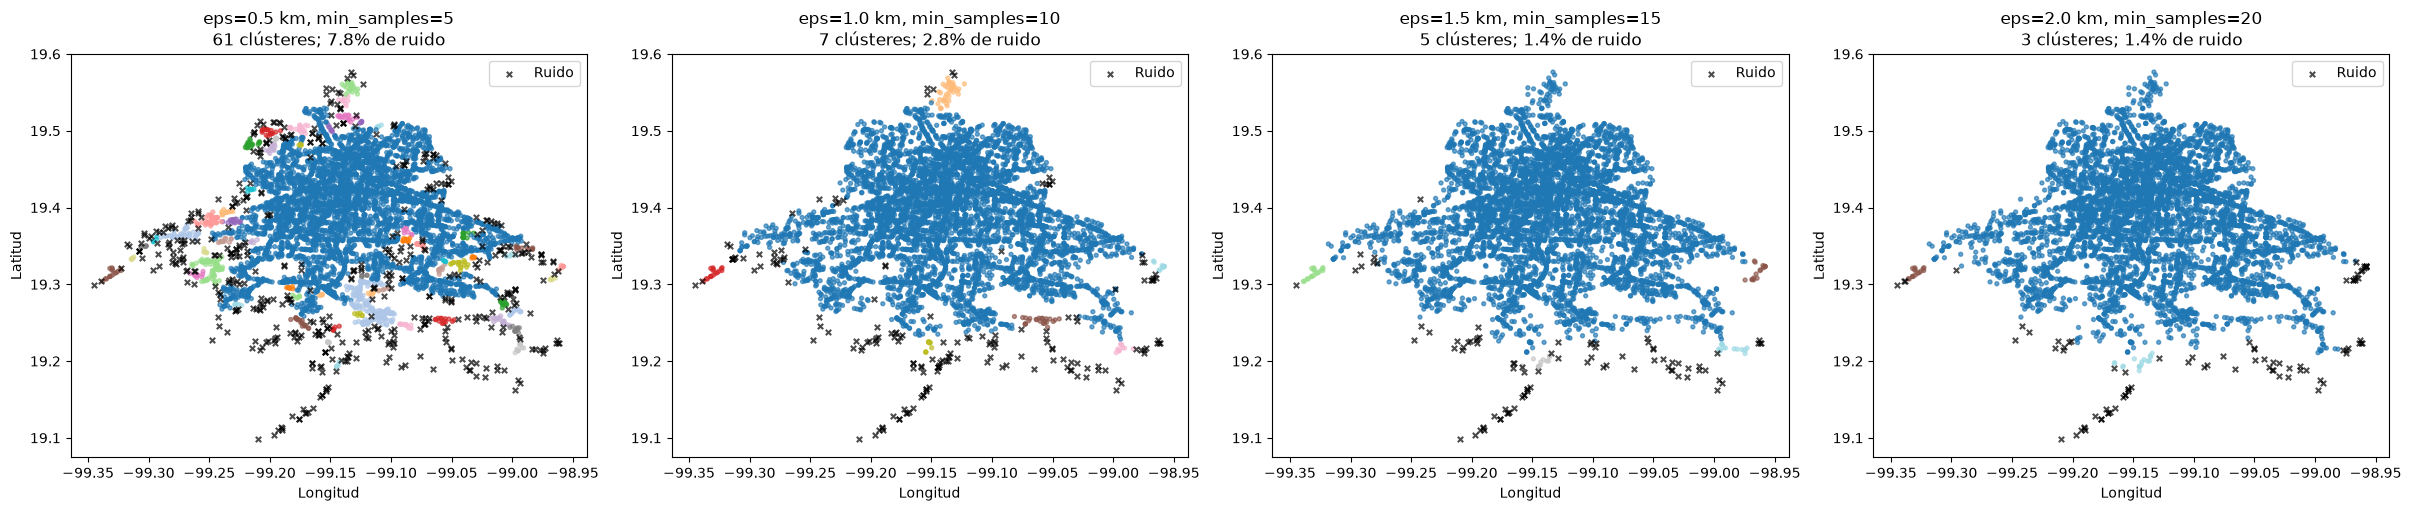

In [54]:
# df_geo debe conservar el mismo orden usado para crear coordenadas
df_geo = df.reset_index(drop=True).copy()

fig, axes = plt.subplots(
    1,
    len(etiquetas_por_modelo),
    figsize=(6 * len(etiquetas_por_modelo), 5),
    constrained_layout=True
)

axes = np.atleast_1d(axes)

for ax, (nombre_modelo, etiquetas) in zip(
    axes,
    etiquetas_por_modelo.items()
):
    mascara_ruido = etiquetas == -1
    numero_clusters = len(set(etiquetas) - {-1})
    proporcion_ruido = mascara_ruido.mean()

    ax.scatter(
        coordenadas[~mascara_ruido, 1],
        coordenadas[~mascara_ruido, 0],
        c=etiquetas[~mascara_ruido],
        cmap="tab20",
        s=8,
        alpha=0.65
    )

    ax.scatter(
        coordenadas[mascara_ruido, 1],
        coordenadas[mascara_ruido, 0],
        color="black",
        marker="x",
        s=15,
        alpha=0.7,
        label="Ruido"
    )

    ax.set_title(
        f"{nombre_modelo}\n"
        f"{numero_clusters} clústeres; {proporcion_ruido:.1%} de ruido"
    )
    ax.set_xlabel("Longitud")
    ax.set_ylabel("Latitud")
    ax.legend()

plt.show()

In [55]:
df_muestra['clas_con_f_alarma'].unique()

<StringArray>
['URGENCIAS MEDICAS', 'EMERGENCIA', 'DELITO', 'FALSA ALARMA']
Length: 4, dtype: str

## Clúster 1

In [56]:
#nombre_modelo = 'eps=1.5 km, min_samples=15'
nombre_modelo = 'eps=0.5 km, min_samples=5'

etiquetas = etiquetas_por_modelo[nombre_modelo]

muestra_modelo = df_muestra.reset_index(drop=True).copy()

if len(etiquetas) != len(muestra_modelo):
    raise ValueError(
        "Las etiquetas y df_muestra deben tener el mismo número de filas."
    )

muestra_modelo['cluster_dbscan'] = np.asarray(etiquetas)

muestra_modelo['es_F'] = (
    muestra_modelo['codigo_cierre']
    .astype(str)
    .str.strip()
    .str.upper()
    .eq('F')
)

resumen_F = (
    muestra_modelo
    .groupby('cluster_dbscan')
    .agg(
        total_reportes=('codigo_cierre', 'size'),
        conteo_F=('es_F', 'sum')
    )
    .reset_index()
)

resumen_F['proporcion_F'] = (
    resumen_F['conteo_F'] / resumen_F['total_reportes']
)

resumen_F['tipo'] = np.where(
    resumen_F['cluster_dbscan'] == -1,
    'Ruido',
    'Clúster'
)


resumen_F

,cluster_dbscan,total_reportes,conteo_F,proporcion_F,tipo
0,-1,487,108,0.221766,Ruido
1,0,4737,936,0.197593,Clúster
2,1,62,17,0.274194,Clúster
3,2,68,19,0.279412,Clúster
4,3,12,3,0.250000,Clúster
...,...,...,...,...,...
57,56,4,2,0.500000,Clúster
58,57,5,1,0.200000,Clúster
59,58,5,2,0.400000,Clúster
60,59,4,1,0.250000,Clúster


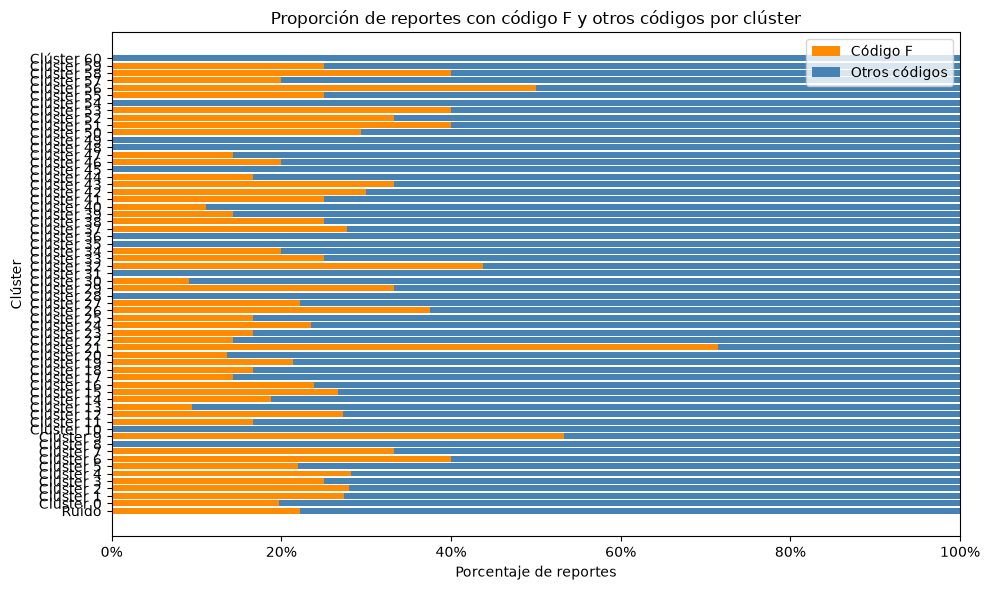

In [57]:
resumen_graf = resumen_F.sort_values('cluster_dbscan').copy()

resumen_graf['grupo'] = resumen_graf['cluster_dbscan'].apply(
    lambda x: 'Ruido' if x == -1 else f'Clúster {int(x)}'
)

resumen_graf['proporcion_no_F'] = 1 - resumen_graf['proporcion_F']

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    resumen_graf['grupo'],
    resumen_graf['proporcion_F'] * 100,
    label='Código F',
    color='darkorange'
)

ax.barh(
    resumen_graf['grupo'],
    resumen_graf['proporcion_no_F'] * 100,
    left=resumen_graf['proporcion_F'] * 100,
    label='Otros códigos',
    color='steelblue'
)

ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.set_xlabel('Porcentaje de reportes')
ax.set_ylabel('Clúster')
ax.set_title('Proporción de reportes con código F y otros códigos por clúster')
ax.legend()

plt.tight_layout()
plt.show()

In [58]:
cluster_objetivo = 21

muestra_modelo = df_muestra.reset_index(drop=True).copy()
etiquetas = etiquetas_por_modelo[nombre_modelo]

muestra_modelo['cluster_dbscan'] = np.asarray(etiquetas)

filas_cluster = muestra_modelo[
    muestra_modelo['cluster_dbscan'] == cluster_objetivo
]

filas_cluster.head(1)

,folio,fecha_hora_creacion,fecha_hora_cierre,tipo_incidente_c4,incidente_c4,alcaldia_inicio,codigo_cierre,clas_con_f_alarma,tipo_entrada,alcaldia_cierre,alcaldia_catalogo,colonia_catalogo,longitud,latitud,cordenada_fuera_cdmx,cluster_dbscan
264,C5/20230708/03680,2023-07-08 16:12:23,2023-07-08 19:19:57,Accidente,Choque sin lesionados,TLAHUAC,F,EMERGENCIA,LLAMADA DEL 911,TLAHUAC,Tláhuac,NaN,-98.958046,19.32321,False,21


In [59]:
filas_cluster['alcaldia_inicio'].unique()

<StringArray>
['TLAHUAC']
Length: 1, dtype: str

## Clúster 2

In [60]:
#nombre_modelo = 'eps=1.5 km, min_samples=15'
nombre_modelo = 'eps=1.0 km, min_samples=10'

etiquetas = etiquetas_por_modelo[nombre_modelo]

muestra_modelo = df_muestra.reset_index(drop=True).copy()

if len(etiquetas) != len(muestra_modelo):
    raise ValueError(
        "Las etiquetas y df_muestra deben tener el mismo número de filas."
    )

muestra_modelo['cluster_dbscan'] = np.asarray(etiquetas)

muestra_modelo['es_F'] = (
    muestra_modelo['codigo_cierre']
    .astype(str)
    .str.strip()
    .str.upper()
    .eq('F')
)

resumen_F = (
    muestra_modelo
    .groupby('cluster_dbscan')
    .agg(
        total_reportes=('codigo_cierre', 'size'),
        conteo_F=('es_F', 'sum')
    )
    .reset_index()
)

resumen_F['proporcion_F'] = (
    resumen_F['conteo_F'] / resumen_F['total_reportes']
)

resumen_F['tipo'] = np.where(
    resumen_F['cluster_dbscan'] == -1,
    'Ruido',
    'Clúster'
)


resumen_F

,cluster_dbscan,total_reportes,conteo_F,proporcion_F,tipo
0,-1,172,40,0.232558,Ruido
1,0,5929,1201,0.202564,Clúster
2,1,39,6,0.153846,Clúster
3,2,17,7,0.411765,Clúster
4,3,24,7,0.291667,Clúster
5,4,11,2,0.181818,Clúster
6,5,11,2,0.181818,Clúster
7,6,10,5,0.500000,Clúster


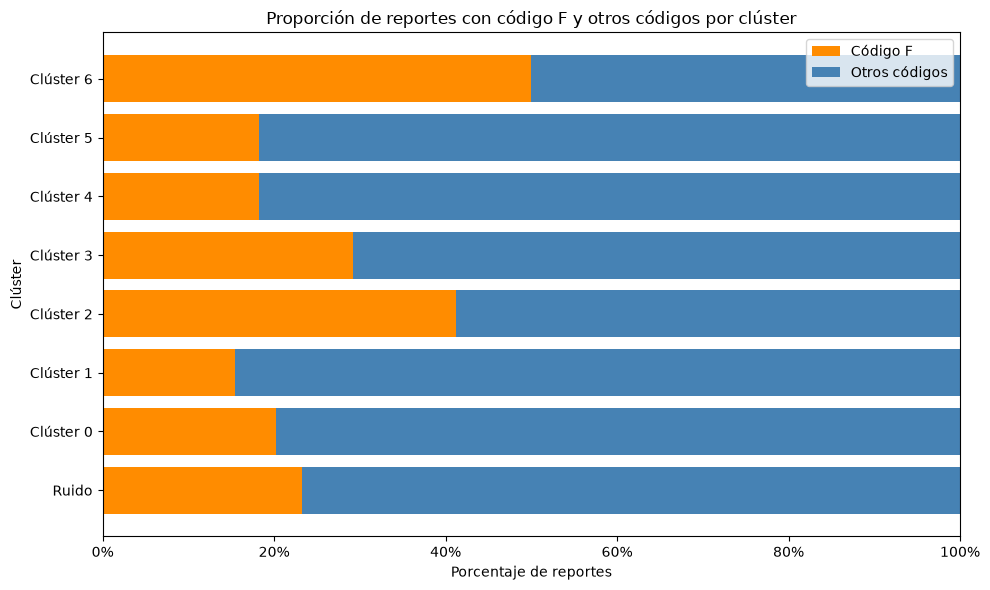

In [61]:
resumen_graf = resumen_F.sort_values('cluster_dbscan').copy()

resumen_graf['grupo'] = resumen_graf['cluster_dbscan'].apply(
    lambda x: 'Ruido' if x == -1 else f'Clúster {int(x)}'
)

resumen_graf['proporcion_no_F'] = 1 - resumen_graf['proporcion_F']

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    resumen_graf['grupo'],
    resumen_graf['proporcion_F'] * 100,
    label='Código F',
    color='darkorange'
)

ax.barh(
    resumen_graf['grupo'],
    resumen_graf['proporcion_no_F'] * 100,
    left=resumen_graf['proporcion_F'] * 100,
    label='Otros códigos',
    color='steelblue'
)

ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.set_xlabel('Porcentaje de reportes')
ax.set_ylabel('Clúster')
ax.set_title('Proporción de reportes con código F y otros códigos por clúster')
ax.legend()

plt.tight_layout()
plt.show()

In [62]:
cluster_objetivo = 6

muestra_modelo = df_muestra.reset_index(drop=True).copy()
etiquetas = etiquetas_por_modelo[nombre_modelo]

muestra_modelo['cluster_dbscan'] = np.asarray(etiquetas)

filas_cluster = muestra_modelo[
    muestra_modelo['cluster_dbscan'] == cluster_objetivo
]

filas_cluster.head(1)

,folio,fecha_hora_creacion,fecha_hora_cierre,tipo_incidente_c4,incidente_c4,alcaldia_inicio,codigo_cierre,clas_con_f_alarma,tipo_entrada,alcaldia_cierre,alcaldia_catalogo,colonia_catalogo,longitud,latitud,cordenada_fuera_cdmx,cluster_dbscan
264,C5/20230708/03680,2023-07-08 16:12:23,2023-07-08 19:19:57,Accidente,Choque sin lesionados,TLAHUAC,F,EMERGENCIA,LLAMADA DEL 911,TLAHUAC,Tláhuac,NaN,-98.958046,19.32321,False,6


In [63]:
filas_cluster['alcaldia_inicio'].unique()

<StringArray>
['TLAHUAC', 'IZTAPALAPA']
Length: 2, dtype: str

## Clúster 3

In [64]:
nombre_modelo = 'eps=1.5 km, min_samples=15'

etiquetas = etiquetas_por_modelo[nombre_modelo]

muestra_modelo = df_muestra.reset_index(drop=True).copy()

if len(etiquetas) != len(muestra_modelo):
    raise ValueError(
        "Las etiquetas y df_muestra deben tener el mismo número de filas."
    )

muestra_modelo['cluster_dbscan'] = np.asarray(etiquetas)

muestra_modelo['es_F'] = (
    muestra_modelo['codigo_cierre']
    .astype(str)
    .str.strip()
    .str.upper()
    .eq('F')
)

resumen_F = (
    muestra_modelo
    .groupby('cluster_dbscan')
    .agg(
        total_reportes=('codigo_cierre', 'size'),
        conteo_F=('es_F', 'sum')
    )
    .reset_index()
)

resumen_F['proporcion_F'] = (
    resumen_F['conteo_F'] / resumen_F['total_reportes']
)

resumen_F['tipo'] = np.where(
    resumen_F['cluster_dbscan'] == -1,
    'Ruido',
    'Clúster'
)


resumen_F

,cluster_dbscan,total_reportes,conteo_F,proporcion_F,tipo
0,-1,87,22,0.252874,Ruido
1,0,6064,1230,0.202836,Clúster
2,1,18,8,0.444444,Clúster
3,2,17,7,0.411765,Clúster
4,3,12,0,0.000000,Clúster
5,4,15,3,0.200000,Clúster


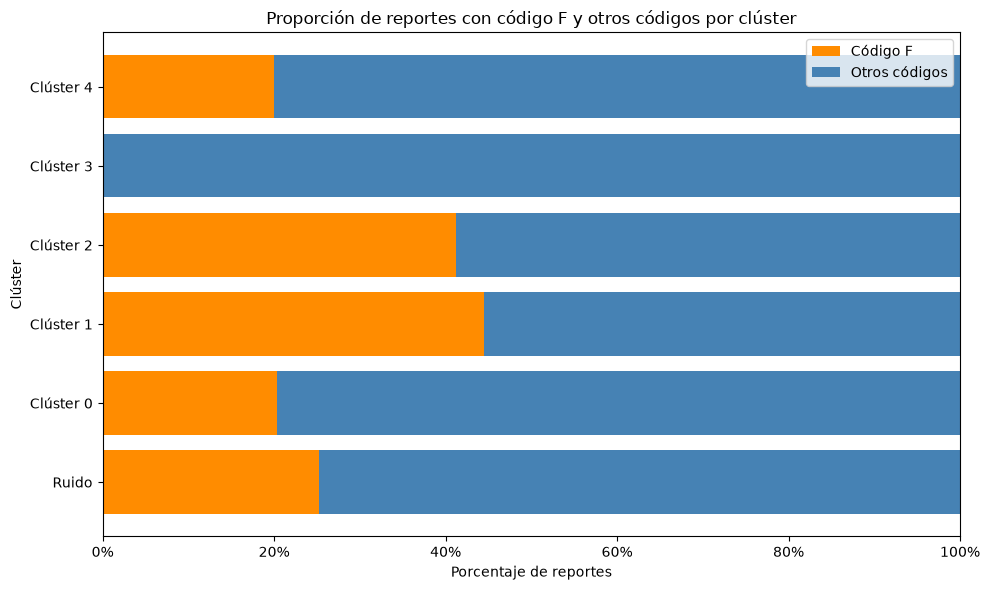

In [65]:
resumen_graf = resumen_F.sort_values('cluster_dbscan').copy()

resumen_graf['grupo'] = resumen_graf['cluster_dbscan'].apply(
    lambda x: 'Ruido' if x == -1 else f'Clúster {int(x)}'
)

resumen_graf['proporcion_no_F'] = 1 - resumen_graf['proporcion_F']

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    resumen_graf['grupo'],
    resumen_graf['proporcion_F'] * 100,
    label='Código F',
    color='darkorange'
)

ax.barh(
    resumen_graf['grupo'],
    resumen_graf['proporcion_no_F'] * 100,
    left=resumen_graf['proporcion_F'] * 100,
    label='Otros códigos',
    color='steelblue'
)

ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.set_xlabel('Porcentaje de reportes')
ax.set_ylabel('Clúster')
ax.set_title('Proporción de reportes con código F y otros códigos por clúster')
ax.legend()

plt.tight_layout()
plt.show()

In [67]:
nombre_modelo = 'eps=1.5 km, min_samples=15'
cluster_objetivo = 3

muestra_modelo = df_muestra.reset_index(drop=True).copy()
etiquetas = etiquetas_por_modelo[nombre_modelo]

muestra_modelo['cluster_dbscan'] = np.asarray(etiquetas)

filas_cluster = muestra_modelo[
    muestra_modelo['cluster_dbscan'] == cluster_objetivo
]

filas_cluster.head(1)

,folio,fecha_hora_creacion,fecha_hora_cierre,tipo_incidente_c4,incidente_c4,alcaldia_inicio,codigo_cierre,clas_con_f_alarma,tipo_entrada,alcaldia_cierre,alcaldia_catalogo,colonia_catalogo,longitud,latitud,cordenada_fuera_cdmx,cluster_dbscan
256,C5/20220826/05229,2022-08-26 23:48:25,2022-08-27 00:17:51,Accidente,Choque sin lesionados,TLALPAN,D,EMERGENCIA,LLAMADA DEL 911,TLALPAN,Tlalpan,Pueblo San Miguel Topilejo,-99.138111,19.200021,False,3


In [66]:
# No hay casos de falsas llamadas 
filas_cluster['codigo_cierre'].unique()

<StringArray>
['F', 'A', 'D']
Length: 3, dtype: str

In [69]:
filas_cluster['alcaldia_inicio'].unique()

<StringArray>
['TLALPAN']
Length: 1, dtype: str

## Clúster 4

In [70]:
#nombre_modelo = 'eps=1.5 km, min_samples=15'
nombre_modelo = 'eps=2.0 km, min_samples=20'

etiquetas = etiquetas_por_modelo[nombre_modelo]

muestra_modelo = df_muestra.reset_index(drop=True).copy()

if len(etiquetas) != len(muestra_modelo):
    raise ValueError(
        "Las etiquetas y df_muestra deben tener el mismo número de filas."
    )

muestra_modelo['cluster_dbscan'] = np.asarray(etiquetas)

muestra_modelo['es_F'] = (
    muestra_modelo['codigo_cierre']
    .astype(str)
    .str.strip()
    .str.upper()
    .eq('F')
)

resumen_F = (
    muestra_modelo
    .groupby('cluster_dbscan')
    .agg(
        total_reportes=('codigo_cierre', 'size'),
        conteo_F=('es_F', 'sum')
    )
    .reset_index()
)

resumen_F['proporcion_F'] = (
    resumen_F['conteo_F'] / resumen_F['total_reportes']
)

resumen_F['tipo'] = np.where(
    resumen_F['cluster_dbscan'] == -1,
    'Ruido',
    'Clúster'
)


resumen_F

,cluster_dbscan,total_reportes,conteo_F,proporcion_F,tipo
0,-1,86,26,0.302326,Ruido
1,0,6094,1236,0.202822,Clúster
2,1,16,7,0.437500,Clúster
3,2,17,1,0.058824,Clúster


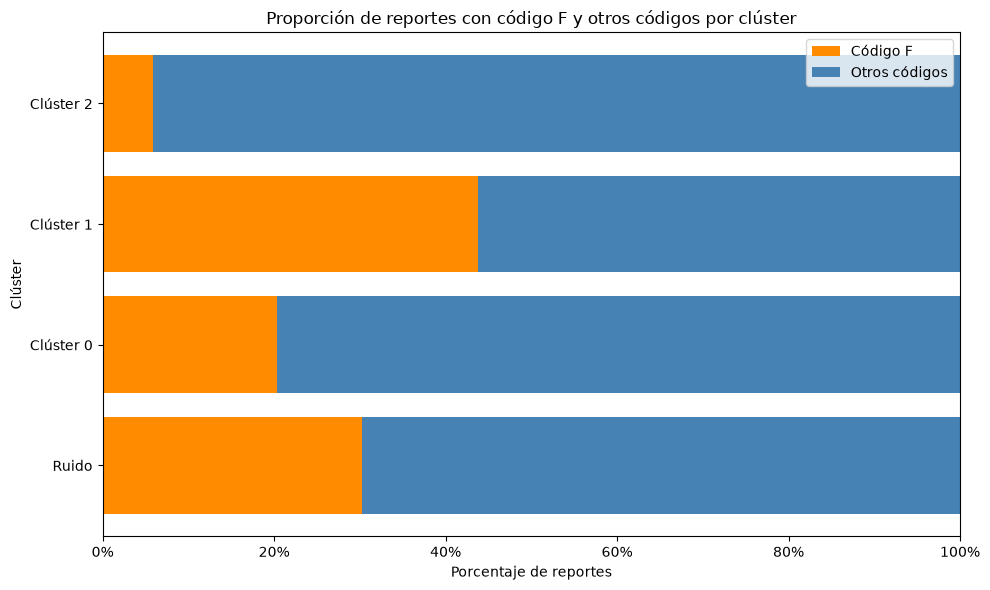

In [71]:
resumen_graf = resumen_F.sort_values('cluster_dbscan').copy()

resumen_graf['grupo'] = resumen_graf['cluster_dbscan'].apply(
    lambda x: 'Ruido' if x == -1 else f'Clúster {int(x)}'
)

resumen_graf['proporcion_no_F'] = 1 - resumen_graf['proporcion_F']

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    resumen_graf['grupo'],
    resumen_graf['proporcion_F'] * 100,
    label='Código F',
    color='darkorange'
)

ax.barh(
    resumen_graf['grupo'],
    resumen_graf['proporcion_no_F'] * 100,
    left=resumen_graf['proporcion_F'] * 100,
    label='Otros códigos',
    color='steelblue'
)

ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.set_xlabel('Porcentaje de reportes')
ax.set_ylabel('Clúster')
ax.set_title('Proporción de reportes con código F y otros códigos por clúster')
ax.legend()

plt.tight_layout()
plt.show()

In [72]:
cluster_objetivo = 2

muestra_modelo = df_muestra.reset_index(drop=True).copy()
etiquetas = etiquetas_por_modelo[nombre_modelo]

muestra_modelo['cluster_dbscan'] = np.asarray(etiquetas)

filas_cluster = muestra_modelo[
    muestra_modelo['cluster_dbscan'] == cluster_objetivo
]

filas_cluster.head(1)

,folio,fecha_hora_creacion,fecha_hora_cierre,tipo_incidente_c4,incidente_c4,alcaldia_inicio,codigo_cierre,clas_con_f_alarma,tipo_entrada,alcaldia_cierre,alcaldia_catalogo,colonia_catalogo,longitud,latitud,cordenada_fuera_cdmx,cluster_dbscan
25,C5/20220122/02843,2022-01-22 16:14:37,2022-01-22 19:18:07,Accidente,Choque con lesionados,TLALPAN,A,URGENCIAS MEDICAS,LLAMADA DEL 911,TLALPAN,Tlalpan,NaN,-99.145054,19.187242,False,2


In [73]:
filas_cluster['alcaldia_inicio'].unique()

<StringArray>
['TLALPAN']
Length: 1, dtype: str

Es interesante notar cómo se distribuyen porcentualmente las falsas alarmas, ya que si analizamos muchas veces los números absolutos se obtiene un número muy grande. En general, todos los clústers número 1 tuvieron un número absoluto más alto de falsas alarmas, pero en términos relativos eran muy similares a otros clústers.

En otras palabras que un clúster concentre muchos reportes no significa que tenga una mayor tasa de falsas alarmas. Para comparar las zonas, debemos revisar la proporción de reportes F respecto al total de reportes de cada clúster. Además, el resultado depende de la muestra y de los parámetros utilizados; DBSCAN muestra dónde se agrupan los reportes, pero no explica por qué se concentran ahí ni determina por sí solo si existe una mayor incidencia de falsas alarmas.

Limitaciones: DBSCAN identifica grupos de reportes que se encuentran cerca entre sí y tienen una concentración suficiente según los parámetros definidos. En este caso, eps establece la distancia máxima entre reportes vecinos y min_samples el número mínimo de reportes cercanos para formar un clúster. Al cambiar estos parámetros, los grupos pueden dividirse o unirse y también puede cambiar la cantidad de observaciones clasificadas como ruido. Como en nuestras pruebas cambiaron ambos parámetros al mismo tiempo, no podemos identificar por separado el efecto de cada uno.

## Pregunta de reflexión

DBSCAN ayuda a tener una mejor perspectiva espacial que no es tan fácil de apreciar en la construcción del modelo supervizado, al agrupar reportes cercanos según su ubicación. Así es más fácil ver si los reportes se concentran en ciertas zonas y después esto podría ayudar en la generación de variables que mejoren el poder predictivo de los modelos.

## Limitaciones 
Con DBSCAN no tenemos una etiqueta de contraste para ver qué tan bien lo esta haciendo el modelo. Además, tampoco podemos utilizar éste método si nuestro interés es predecir.